# RQ1 · Step 1: How many IDRiD lesions survive resizing?

**Question:** our restorers work at **256 px** and our classifiers at **384 px**, but IDRiD photos are **4288 × 2848 px**.
How many lesions are still visible after shrinking, *before any restorer touches the image*?

**Why it matters:** if a microaneurysm has already vanished from resizing, we must not blame the restorer for "erasing" it.
This result decides the working resolution for the whole lesion audit.

**What this notebook does**
1. Finds the IDRiD images and lesion masks
2. Shows you what each lesion type looks like
3. Counts lesions with *connected components*
4. Measures every lesion's size at 4288 px, 1024, 512, 384 and 256
5. Shows a real microaneurysm at each size, so you can see it fade
6. Saves a summary table and a figure

**Done when:** you have `summary.csv` + `lesion_size_hist.png` and have looked at the zoom figure in section 5.

Uses only the clinicians' masks: no models and no GPU. Runs on your Mac in a minute or two.

In [4]:
# If a package is missing, install it in your environment first, e.g.:
#   uv pip install numpy scipy pillow pandas matplotlib
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

Image.MAX_IMAGE_PIXELS = None   # IDRiD images are large; this silences PIL's size warning

# >>> EDIT THIS to where you unzipped "A. Segmentation.zip"
IDRID = Path("../../data/raw/idrid/A. Segmentation").expanduser()
OUT   = Path("../../results/Idrid/step1_lesion_scale").expanduser()
OUT.mkdir(parents=True, exist_ok=True)

LESIONS = {"MA": "Microaneurysms", "HE": "Haemorrhages", "EX": "Hard exudates", "SE": "Soft exudates"}
COLOURS = {"MA": (255, 0, 0), "HE": (0, 255, 0), "EX": (255, 255, 0), "SE": (0, 200, 255)}
TARGETS = [1024, 512, 384, 256]   # working sizes we care about (longest side, after padding to square)
MIN_PX  = 2.0                     # a lesion narrower than ~2 px is basically gone

print("IDRiD folder exists:", IDRID.exists())

IDRiD folder exists: True


## 1. Find the images and masks

IDRiD names files like `IDRiD_01.jpg` (the photo) and `IDRiD_01_MA.tif` (its microaneurysm mask).
Not every image has every lesion type: for example, many images have no soft-exudate mask.

In [5]:
img_pat  = re.compile(r"^(IDRiD_\d+)\.jpe?g$", re.I)
mask_pat = re.compile(r"^(IDRiD_\d+)_(MA|HE|EX|SE)\.tif$", re.I)

images = {m.group(1): p for p in IDRID.rglob("*") if (m := img_pat.match(p.name))}
masks  = {}
for p in IDRID.rglob("*.tif"):
    if m := mask_pat.match(p.name):
        masks.setdefault(m.group(1), {})[m.group(2).upper()] = p

print(f"{len(images)} images, {len(masks)} images with at least one lesion mask")
print("Images with each mask type:",
      {code: sum(code in v for v in masks.values()) for code in LESIONS})
example_id = sorted(masks, key=lambda i: len(masks[i]), reverse=True)[0]
print("Example image used below:", example_id, "with masks", sorted(masks[example_id]))

81 images, 81 images with at least one lesion mask
Images with each mask type: {'MA': 81, 'HE': 80, 'EX': 81, 'SE': 40}
Example image used below: IDRiD_03 with masks ['EX', 'HE', 'MA', 'SE']


## 2. Look at the lesions

Colours: **red = microaneurysms**, **green = haemorrhages**, **yellow = hard exudates**, **blue = soft exudates**.

Look closely at the red dots: they are tiny even at full resolution. That is the whole problem.

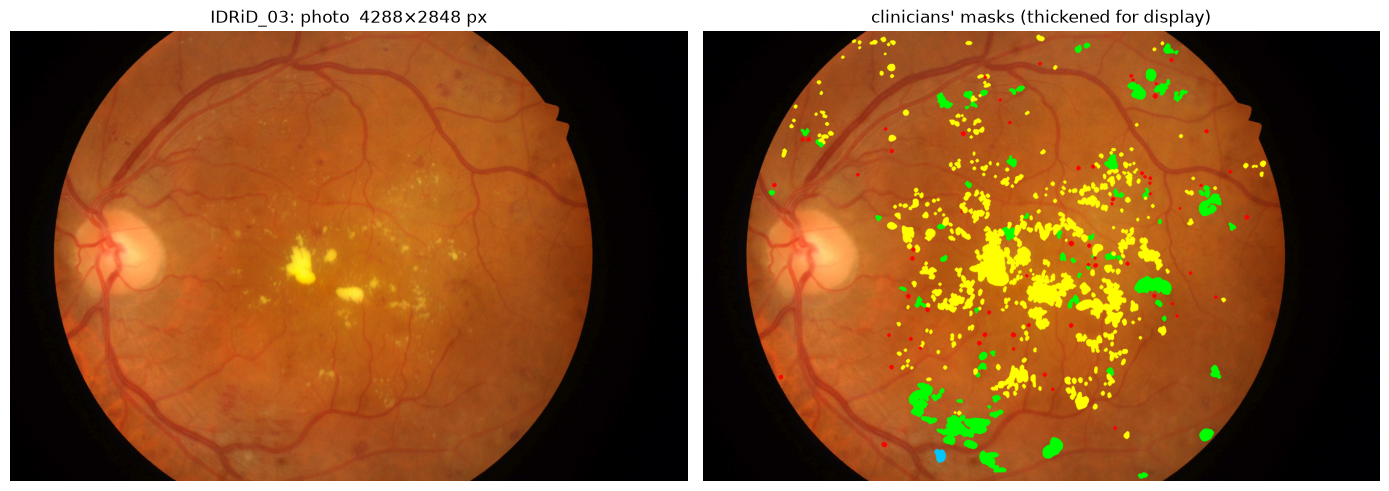

In [6]:
def load_mask(path):
    return np.array(Image.open(path).convert("L")) > 0

img = np.array(Image.open(images[example_id]).convert("RGB"))
overlay = img.copy()
for code, path in masks[example_id].items():
    m = load_mask(path)
    m = ndimage.binary_dilation(m, iterations=6)   # thicken only for display, so tiny lesions are visible
    overlay[m] = COLOURS[code]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(img); ax[0].set_title(f"{example_id}: photo  {img.shape[1]}×{img.shape[0]} px")
ax[1].imshow(overlay); ax[1].set_title("clinicians' masks (thickened for display)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Count lesions with connected components

A mask is just a black-and-white picture. One **lesion** = one **connected blob** of white pixels.
`scipy.ndimage.label` gives every blob its own number, so counting blobs counts lesions.
We use **8-connectivity**: pixels touching diagonally belong to the same blob.

The **area** of a blob is its number of pixels. To talk about size in an intuitive way we convert area to an
**equivalent diameter**: the width of a circle with the same area, `d = 2·√(area/π)`.

In [7]:
m = load_mask(masks[example_id]["MA"]) if "MA" in masks[example_id] else load_mask(next(iter(masks[example_id].values())))
labels, n = ndimage.label(m, structure=np.ones((3, 3)))
areas = np.bincount(labels.ravel())[1:]
diam = 2 * np.sqrt(areas / np.pi)
print(f"{n} lesions in this mask")
print(f"area (px):      min {areas.min()}, median {np.median(areas):.0f}, max {areas.max()}")
print(f"diameter (px):  min {diam.min():.1f}, median {np.median(diam):.1f}, max {diam.max():.1f}")

63 lesions in this mask
area (px):      min 17, median 162, max 460
diameter (px):  min 4.7, median 14.4, max 24.2


## 4. Measure every lesion at every working size

We first **pad the photo to a square** (black bars top and bottom) so shrinking keeps circles round,
then shrink the longest side to the target size. The scale factor is the same in both directions:
`scale = target / 4288`. A lesion's diameter shrinks by that factor.

For comparison we also compute the **thesis-style squash** to 256×256 (different scale for width and height),
which is what the OMIA pipeline did.

In [8]:
rows = []
for image_id, per_type in sorted(masks.items()):
    for code, path in per_type.items():
        m = load_mask(path)
        h, w = m.shape
        lab, n = ndimage.label(m, structure=np.ones((3, 3)))
        if n == 0:
            continue
        areas = np.bincount(lab.ravel())[1:]
        split = "test" if "test" in str(path).lower() else "train"
        for a in areas:
            r = dict(image_id=image_id, split=split, lesion=code, area_native=int(a),
                     diam_native=2 * np.sqrt(a / np.pi))
            side = max(h, w)
            for t in TARGETS:                                   # pad to square, then uniform resize
                s = t / side
                r[f"diam_{t}"] = r["diam_native"] * s
            sx, sy = 256 / w, 256 / h                           # thesis: squash straight to 256x256
            r["diam_256_thesis_squash"] = 2 * np.sqrt(a * sx * sy / np.pi)
            rows.append(r)

df = pd.DataFrame(rows)
df.to_csv(OUT / "lesions_per_component.csv", index=False)
print(f"{len(df)} lesions measured across {df.image_id.nunique()} images")
df.head()

17189 lesions measured across 81 images


,image_id,split,lesion,area_native,diam_native,diam_1024,diam_512,diam_384,diam_256,diam_256_thesis_squash
0,IDRiD_01,train,HE,4346,74.387493,17.764177,8.882089,6.661567,4.441044,5.449322
1,IDRiD_01,train,HE,1979,50.197022,11.987349,5.993674,4.495256,2.996837,3.677228
2,IDRiD_01,train,HE,252,17.912464,4.277603,2.138802,1.604101,1.069401,1.312194
3,IDRiD_01,train,HE,651,28.790258,6.875285,3.437643,2.578232,1.718821,2.109056
4,IDRiD_01,train,HE,1369,41.750029,9.970156,4.985078,3.738809,2.492539,3.058436


In [9]:
size_cols = [f"diam_{t}" for t in TARGETS] + ["diam_256_thesis_squash"]
summary = []
for code, name in LESIONS.items():
    d = df[df.lesion == code]
    if d.empty:
        continue
    row = {"lesion": name, "n_lesions": len(d), "n_images": d.image_id.nunique(),
           "median diameter @4288 (px)": round(d.diam_native.median(), 1)}
    for c in size_cols:
        label = c.replace("diam_", "% visible @").replace("_thesis_squash", " (thesis squash)")
        row[label] = round(100 * (d[c] >= MIN_PX).mean(), 1)
    summary.append(row)
summary = pd.DataFrame(summary)
summary.to_csv(OUT / "summary.csv", index=False)
summary

,lesion,n_lesions,n_images,median diameter @4288 (px),% visible @1024,% visible @512,% visible @384,% visible @256,% visible @256 (thesis squash)
0,Microaneurysms,3497,81,17.3,98.6,53.3,23.2,2.3,8.9
1,Haemorrhages,1900,80,45.2,100.0,98.1,92.2,70.2,83.9
2,Hard exudates,11642,81,16.6,93.0,49.5,32.6,16.0,23.1
3,Soft exudates,150,40,105.0,100.0,100.0,100.0,99.3,100.0


**How to read it:** "% visible @256" is the share of lesions at least 2 px wide after shrinking to 256.
If that number is low for microaneurysms, they vanish from resizing alone, before any restorer acts.

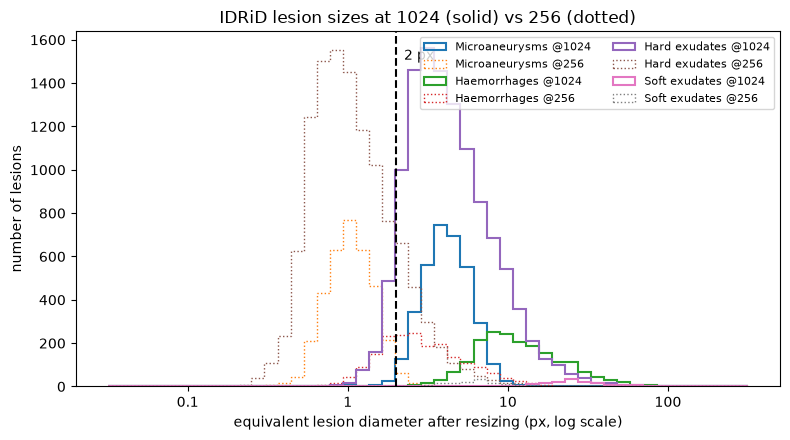

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(-1.5, 2.5, 50)
for code, name in LESIONS.items():
    d = df[df.lesion == code]
    if not d.empty:
        ax.hist(np.log10(d["diam_1024"].clip(lower=10**-1.5)), bins=bins, histtype="step", lw=1.5, label=f"{name} @1024")
        ax.hist(np.log10(d["diam_256"].clip(lower=10**-1.5)), bins=bins, histtype="step", lw=1, ls=":", label=f"{name} @256")
ax.axvline(np.log10(MIN_PX), c="k", ls="--"); ax.text(np.log10(MIN_PX), ax.get_ylim()[1]*0.95, f"  {MIN_PX:g} px", va="top")
ax.set_xticks([-1, 0, 1, 2]); ax.set_xticklabels(["0.1", "1", "10", "100"])
ax.set_xlabel("equivalent lesion diameter after resizing (px, log scale)")
ax.set_ylabel("number of lesions")
ax.set_title("IDRiD lesion sizes at 1024 (solid) vs 256 (dotted)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); fig.savefig(OUT / "lesion_size_hist.png", dpi=150); plt.show()

## 5. See it with your own eyes

Numbers are convincing, but seeing is better. We take one microaneurysm, crop a small window around it,
and show what that same window looks like after the **whole photo** is padded and shrunk to each size
(then blown back up with big blocky pixels so you can compare).

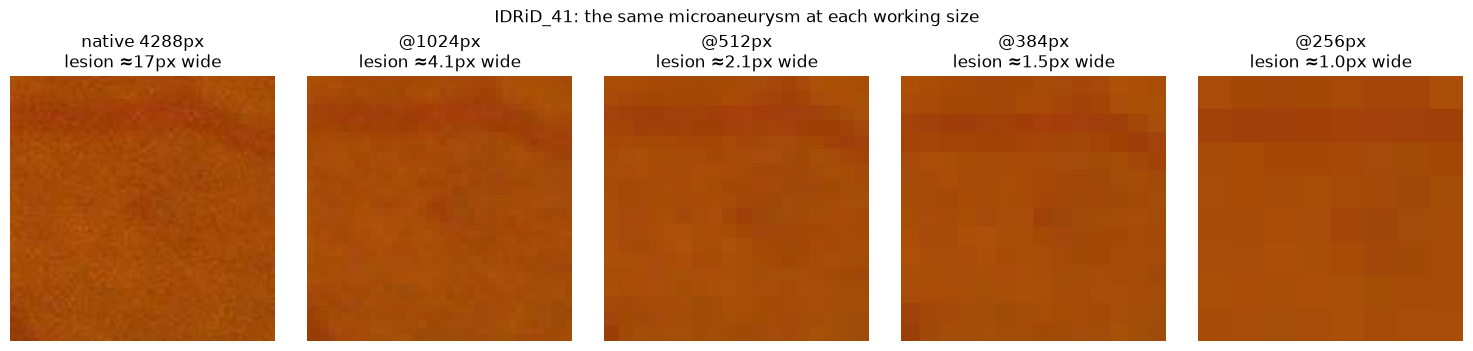

In [11]:
def pad_square(arr):
    h, w = arr.shape[:2]
    side = max(h, w)
    out = np.zeros((side, side) + arr.shape[2:], dtype=arr.dtype)
    y0, x0 = (side - h) // 2, (side - w) // 2
    out[y0:y0 + h, x0:x0 + w] = arr
    return out, y0, x0

# pick the microaneurysm closest to the median size, so the example is typical
code_ = "MA" if (df.lesion == "MA").any() else df.lesion.iloc[0]
row = df[df.lesion == code_].iloc[(df[df.lesion == code_].diam_native - df[df.lesion == code_].diam_native.median()).abs().argsort().iloc[0]]
mid = row.image_id
m = load_mask(masks[mid][code_])
lab, _ = ndimage.label(m, structure=np.ones((3, 3)))
target_area = row.area_native
comp = [i for i, a in enumerate(np.bincount(lab.ravel())[1:], start=1) if a == target_area][0]
cy, cx = [int(v) for v in ndimage.center_of_mass(lab == comp)]

photo = np.array(Image.open(images[mid]).convert("RGB"))
sq, y0, x0 = pad_square(photo)
side = sq.shape[0]
win = 160                                   # window size at native resolution
cy_s, cx_s = cy + y0, cx + x0

fig, ax = plt.subplots(1, len(TARGETS) + 1, figsize=(3 * (len(TARGETS) + 1), 3.4))
crop = sq[cy_s - win // 2: cy_s + win // 2, cx_s - win // 2: cx_s + win // 2]
ax[0].imshow(crop); ax[0].set_title(f"native {side}px\nlesion ≈{row.diam_native:.0f}px wide")
for a_, t in zip(ax[1:], TARGETS):
    s = t / side
    small = np.array(Image.fromarray(sq).resize((t, t), Image.Resampling.LANCZOS))
    yc, xc, hw = int(cy_s * s), int(cx_s * s), max(int(win * s / 2), 2)
    c = small[max(yc - hw, 0): yc + hw, max(xc - hw, 0): xc + hw]
    c = np.array(Image.fromarray(c).resize((win, win), Image.Resampling.NEAREST))
    a_.imshow(c); a_.set_title(f"@{t}px\nlesion ≈{row.diam_native * s:.1f}px wide")
for a_ in ax: a_.axis("off")
plt.suptitle(f"{mid}: the same {LESIONS.get(code_, code_)[:-1].lower()} at each working size", y=1.02)
plt.tight_layout(); fig.savefig(OUT / "zoom_one_lesion.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. What to send back, and what to log

Send Claude:
1. the `summary` table (section 4)
2. `lesion_size_hist.png`
3. `zoom_one_lesion.png`, plus one sentence on what you see at 256

**Log line for your `til` RQ1 log:**
`YYYY-MM-DD · Step 1 · IDRiD lesion sizes vs resize · MA visible @256 = __%, @1024 = __% · decision: ____`

**Decision guide**
- MAs mostly visible at 256 → keep the current pipeline
- MAs vanish at 256 but survive at 1024 → patch-train at 1024 ("train small, restore big")
- MAs vanish even at 1024 → test 1536/2048 in Step 2, or report MAs as below resolution